### DATA PREPROCESSING

In this process, we check for the class distribution to see if we need any balancing and if we do, we use image Data Generator. It seems that there are two classes that have an unbalanced data, so we add more data to their directory (with playing with the image, spinning, zooming, etc). We check for any corrupted image and found none, so we continue forward. We check the class weight as well

Then we train test split the data

Classes found: ['Acral_Lentiginous_Melanoma', 'blue_finger', 'Healthy_Nail', 'Onychogryphosis', 'pitting']

Image counts per class (Before Cleaning):
Acral_Lentiginous_Melanoma: 21
blue_finger: 612
Healthy_Nail: 343
Onychogryphosis: 600
pitting: 629


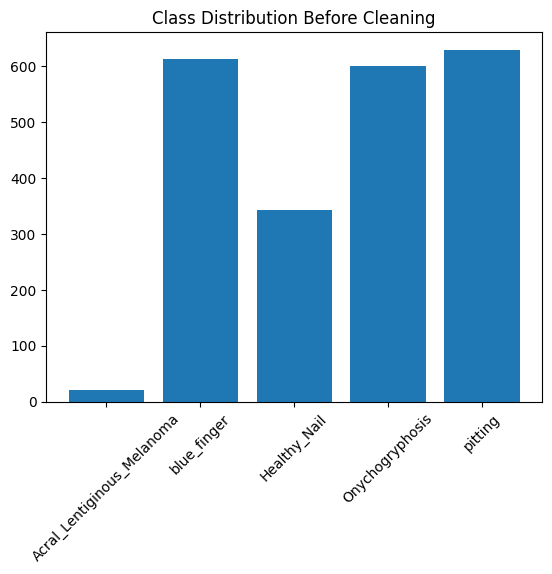


Corrupted images found: 0
Corrupted images removed.

Image counts per class (After Cleaning):
Acral_Lentiginous_Melanoma: 21
blue_finger: 612
Healthy_Nail: 343
Onychogryphosis: 600
pitting: 629

=== Augmenting Minority Classes ===
Acral_Lentiginous_Melanoma: 21 → 650 (need +629)
blue_finger: 612 → 650 (need +38)
Healthy_Nail: 343 → 650 (need +307)
Onychogryphosis: 600 → 650 (need +50)
pitting: 629 → 650 (need +21)

Augmentation for minority classes completed.

Image counts per class (After Augmentation):
Acral_Lentiginous_Melanoma: 628
blue_finger: 650
Healthy_Nail: 648
Onychogryphosis: 650
pitting: 650


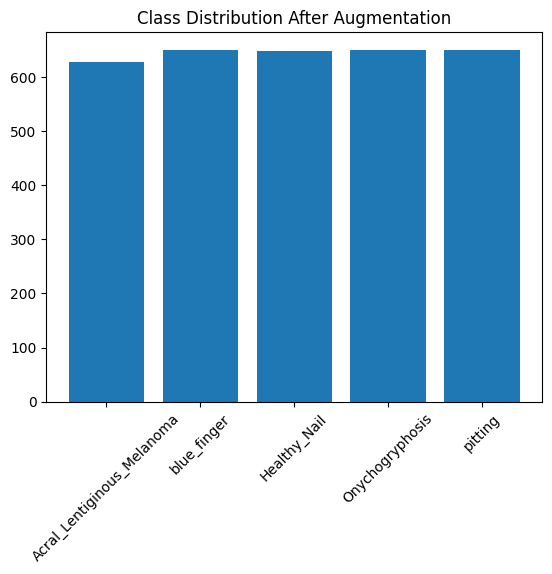


New Class Weights: {0: np.float64(1.0273885350318472), 1: np.float64(0.9926153846153846), 2: np.float64(0.995679012345679), 3: np.float64(0.9926153846153846), 4: np.float64(0.9926153846153846)}
Found 2582 images belonging to 5 classes.
Found 644 images belonging to 5 classes.
Found 644 images belonging to 5 classes.


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array

data_path = r'3B/3B/train'

classes = os.listdir(data_path)

print("Classes found:", classes)

class_counts_before = {cls: len(os.listdir(os.path.join(data_path, cls))) for cls in classes}

print("\nImage counts per class (Before Cleaning):")
for cls, count in class_counts_before.items():
    print(f"{cls}: {count}")

plt.bar(class_counts_before.keys(), class_counts_before.values())
plt.xticks(rotation=45)
plt.title("Class Distribution Before Cleaning")
plt.show()

# Check Any Corrupted Image
corrupted = []

for cls in classes:
    folder = os.path.join(data_path, cls)
    for img_name in os.listdir(folder):
        path = os.path.join(folder, img_name)
        try:
            img = Image.open(path)
            img.verify()
        except:
            corrupted.append(path)

print("\nCorrupted images found:", len(corrupted))

for c in corrupted:
    os.remove(c)

# Recount
class_counts_cleaned = {cls: len(os.listdir(os.path.join(data_path, cls))) for cls in classes}

print("\nImage counts per class (After Cleaning):")
for cls, count in class_counts_cleaned.items():
    print(f"{cls}: {count}")


# Balancing
target_count = 650 

print("\n=== Augmenting Minority Classes ===")

aug = ImageDataGenerator(
    rotation_range=45,
    zoom_range=0.3,
    width_shift_range=0.25,
    height_shift_range=0.25,
    shear_range=0.3,
    horizontal_flip=True,
    vertical_flip=True,
    fill_mode="nearest"
)

for cls in classes:
    cls_path = os.path.join(data_path, cls)
    current_count = len(os.listdir(cls_path))
    
    if current_count >= target_count:
        print(f"{cls}: OK ({current_count} images)")
        continue
    
    needed = target_count - current_count
    print(f"{cls}: {current_count} → {target_count} (need +{needed})")
    
    generated = 0
    
    for img_name in os.listdir(cls_path):
        if generated >= needed:
            break
        
        img_path = os.path.join(cls_path, img_name)
        img = Image.open(img_path)
        img = img.resize((150,150))
        arr = img_to_array(img).reshape(1,150,150,3)
        
        for batch in aug.flow(arr, batch_size=1,
                              save_to_dir=cls_path,
                              save_prefix="aug",
                              save_format="jpg"):
            generated += 1
            if generated >= needed:
                break

print("\nAugmentation for minority classes completed.")

# Recount
class_counts_after_aug = {cls: len(os.listdir(os.path.join(data_path, cls))) for cls in classes}

print("\nImage counts per class (After Augmentation):")
for cls, count in class_counts_after_aug.items():
    print(f"{cls}: {count}")

plt.bar(class_counts_after_aug.keys(), class_counts_after_aug.values())
plt.xticks(rotation=45)
plt.title("Class Distribution After Augmentation")
plt.show()

# Class Weights
labels = []
for cls in class_counts_after_aug:
    labels += [cls] * class_counts_after_aug[cls]

cw = compute_class_weight(
    class_weight="balanced",
    classes=np.array(classes),
    y=labels
)

class_weights = {i: w for i, w in enumerate(cw)}
print("\nNew Class Weights:", class_weights)

# Train Val Generators
IMG_SIZE = (255, 255)

train_datagen = ImageDataGenerator(
    rescale=1/255,
    rotation_range=45,
    width_shift_range=0.25,
    height_shift_range=0.25,
    shear_range=0.3,
    zoom_range=0.3,
    horizontal_flip=True,
    vertical_flip=True,
    fill_mode="nearest",
    validation_split=0.2
)

val_datagen = ImageDataGenerator(
    rescale=1/255,
    validation_split=0.2
)

train_gen = train_datagen.flow_from_directory(
    data_path,
    target_size=IMG_SIZE,
    batch_size=32,
    class_mode="categorical",
    subset="training"
)

val_gen = val_datagen.flow_from_directory(
    data_path,
    target_size=IMG_SIZE,
    batch_size=32,
    class_mode="categorical",
    subset="validation"
)

test_gen = val_datagen.flow_from_directory(
    data_path,
    target_size=IMG_SIZE,
    batch_size=32,
    class_mode="categorical",
    subset="validation",
    shuffle=False
)

### CNN BASELINE

Kode ini mendefinisikan dan melatih model baseline CNN menggunakan Keras. Model terdiri atas tiga lapisan konvolusi (Conv2D) dengan filter bertambah dengan lapisan max pooling unutk mengurangi dimesi, kemudian di flatten dan diteruskan ke dua lapisan dense, dengan aktivasi softmax untuk klasifikasi multi kelas.

c:\Users\Vanessa\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 31s 351ms/step - accuracy: 0.4373 - loss: 1.3625 - val_accuracy: 0.6043 - val_loss: 0.9376
Epoch 2/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 29s 349ms/step - accuracy: 0.6356 - loss: 0.8430 - val_accuracy: 0.6461 - val_loss: 0.8602
Epoch 3/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 29s 348ms/step - accuracy: 0.6973 - loss: 0.7230 - val_accuracy: 0.7589 - val_loss: 0.6309
Epoch 4/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 29s 358ms/step - accuracy: 0.7462 - loss: 0.6283 - val_accuracy: 0.7512 - val_loss: 0.7536
Epoch 5/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 29s 347ms/step - accuracy: 0.7790 - loss: 0.5662 - val_accuracy: 0.7342 - val_loss: 0.8138
Epoch 6/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 29s 355ms/step - accuracy: 0.7694 - loss: 0.5841 - val_accuracy: 0.7527 - val_loss: 0.7525
Epoch 7/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 29s 348ms/step - accuracy: 0.7998 - loss: 0.5279 - val_accuracy: 0.7898 - val_loss: 0.6966
Epoch 8/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 29s 352ms/step - accuracy: 0.7975 - loss: 0.5210 - val_accu

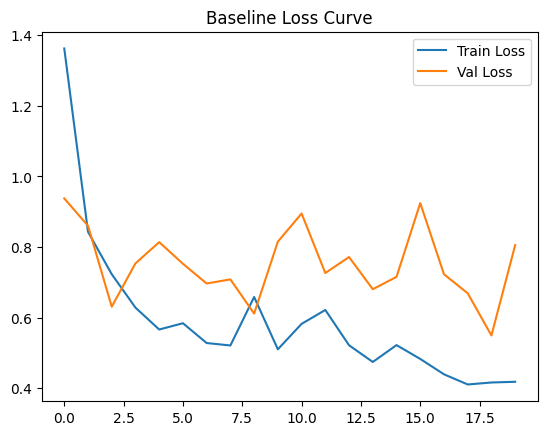

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

baseline = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(150,150,3)),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Flatten(),
    Dense(128, activation='relu'),
    Dense(len(classes), activation='softmax')
])

baseline.compile(optimizer='adam',
                 loss='categorical_crossentropy',
                 metrics=['accuracy'])

history_baseline = baseline.fit(
    train_gen,
    validation_data=val_gen,
    epochs=20,
    class_weight=class_weights
)

plt.plot(history_baseline.history["loss"], label="Train Loss")
plt.plot(history_baseline.history["val_loss"], label="Val Loss")
plt.title("Baseline Loss Curve")
plt.legend()
plt.show()

Model baseline menunjukkan performa yang cukup baik dengan akurasi training meningkat dari 43% menjadi 83%, menandakan bahwa model berhasil mempelajari pola data dengan efektif. Tak hanya itu akurasi validasi pun mencapai 81% meskipun cenderung naik turun, yang menunjukkan adanya sedikit overfitting.

Sebagai model baseline, ini merupakan hasil yang cukup kuat dan menjadi titik awal yang baik sebelum dilakukan pengembangan model lebih lanjut.

### MODIFIED MODEL

Kode tersebut membangun dan melatih model CNN yang telah dimodifikasi dengan menambahkan BatchNormalization dan Dropout agar pelatihan lebih stabil dan mengurangi overfitting

Found 3240 images belonging to 5 classes.
Found 3240 images belonging to 5 classes.
Epoch 1/20
102/102 ━━━━━━━━━━━━━━━━━━━━ 59s 551ms/step - accuracy: 0.7185 - loss: 0.9205 - val_accuracy: 0.2015 - val_loss: 4.3630
Epoch 2/20
102/102 ━━━━━━━━━━━━━━━━━━━━ 56s 547ms/step - accuracy: 0.8145 - loss: 0.5094 - val_accuracy: 0.2281 - val_loss: 4.3052
Epoch 3/20
102/102 ━━━━━━━━━━━━━━━━━━━━ 58s 570ms/step - accuracy: 0.8534 - loss: 0.4180 - val_accuracy: 0.3247 - val_loss: 3.4741
Epoch 4/20
102/102 ━━━━━━━━━━━━━━━━━━━━ 56s 544ms/step - accuracy: 0.8617 - loss: 0.3838 - val_accuracy: 0.4901 - val_loss: 1.8052
Epoch 5/20
102/102 ━━━━━━━━━━━━━━━━━━━━ 55s 542ms/step - accuracy: 0.8769 - loss: 0.3507 - val_accuracy: 0.8139 - val_loss: 0.5126
Epoch 6/20
102/102 ━━━━━━━━━━━━━━━━━━━━ 56s 547ms/step - accuracy: 0.8957 - loss: 0.2991 - val_accuracy: 0.8846 - val_loss: 0.3150
Epoch 7/20
102/102 ━━━━━━━━━━━━━━━━━━━━ 56s 548ms/step - accuracy: 0.9019 - loss: 0.2851 - val_accuracy: 0.9333 - val_loss: 0.1843

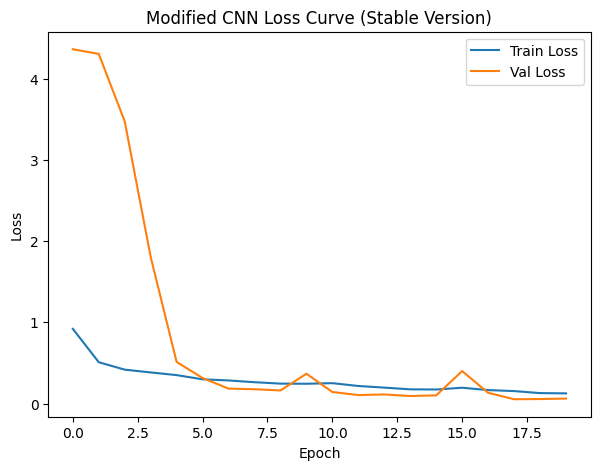

In [ ]:
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam

modified_model = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(150,150,3)),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2,2),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),  

    layers.Dense(train_gen.num_classes, activation='softmax')
])

modified_model.compile(
    optimizer=Adam(learning_rate=0.0001), 
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_mod = modified_model.fit(
    train_gen,
    epochs=20,
    validation_data=val_gen
)

plt.figure(figsize=(7,5))
plt.plot(history_mod.history['loss'], label='Train Loss')
plt.plot(history_mod.history['val_loss'], label='Val Loss')
plt.title("Modified CNN Loss Curve (Stable Version)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()


Model modified menunjukkan peningkatan performa yang sangat signifikan dibanding baseline, dengan akurasi training naik cepat hingga mencapai sekitar 95%, menandakan model mampu mempelajari fitur dengan sangat baik. Salin iut, nilai val_loss terus menurun secara konsisten hingga mencapai sekitar 0.05 yang berarti prediksi model semakin akurat dan stabil

### TRANSFER LEARNING

Kode tersebut menggunakan arsitektur MobileNetV2 sebagai feature extractor dengan bobot ImageNet yang dibekukan agar tidak ikut dilatih, kemudian menambahkan lapisan GlobalAveragePooling, Dense 128 neuron, dan output softmax untuk melakukan klasifikasi sesuai jumlah kelas.

C:\Users\Vanessa\AppData\Local\Temp\ipykernel_9268\2359894244.py:5: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = MobileNetV2(include_top=False, weights="imagenet", input_shape=(150,150,3))


Epoch 1/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 33s 335ms/step - accuracy: 0.8056 - loss: 0.5330 - val_accuracy: 0.8964 - val_loss: 0.3290
Epoch 2/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 25s 307ms/step - accuracy: 0.8943 - loss: 0.3031 - val_accuracy: 0.9042 - val_loss: 0.3234
Epoch 3/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 24s 297ms/step - accuracy: 0.9094 - loss: 0.2550 - val_accuracy: 0.8903 - val_loss: 0.3290
Epoch 4/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 25s 301ms/step - accuracy: 0.9101 - loss: 0.2484 - val_accuracy: 0.8918 - val_loss: 0.3260
Epoch 5/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 24s 296ms/step - accuracy: 0.9144 - loss: 0.2449 - val_accuracy: 0.8918 - val_loss: 0.3359
Epoch 6/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 24s 297ms/step - accuracy: 0.9198 - loss: 0.2233 - val_accuracy: 0.9026 - val_loss: 0.3063
Epoch 7/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 24s 296ms/step - accuracy: 0.8963 - loss: 0.2734 - val_accuracy: 0.8995 - val_loss: 0.3323
Epoch 8/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 24s 295ms/step - accuracy: 0.9175 - loss: 0.2259 - val_accu

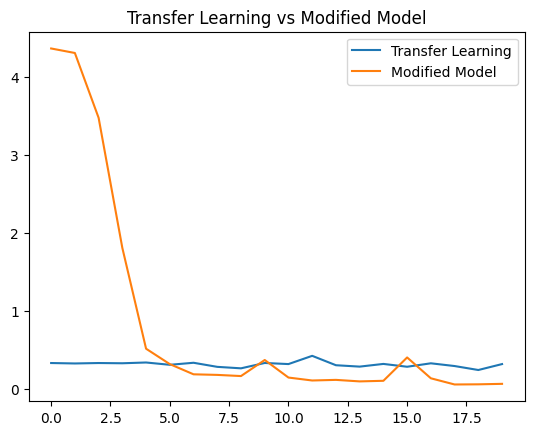

In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D
from tensorflow.keras.models import Model

base = MobileNetV2(include_top=False, weights="imagenet", input_shape=(150,150,3))
base.trainable = False

x = base.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
output = Dense(len(classes), activation='softmax')(x)

transfer = Model(inputs=base.input, outputs=output)

transfer.compile(optimizer='adam',
                 loss='categorical_crossentropy',
                 metrics=['accuracy'])

history_transfer = transfer.fit(
    train_gen,
    validation_data=val_gen,
    epochs=20
)

plt.plot(history_transfer.history["val_loss"], label="Transfer Learning")
plt.plot(history_mod.history["val_loss"], label="Modified Model")
plt.title("Transfer Learning vs Modified Model")
plt.legend()
plt.show()


Model dengan transfer learning menggunakan MobileNetV2 menunjukkan hasil yang sangat baik, dengan akurasi training yang terus meningkat dari 80% menjadi 94% di akhir pelatihan. 

Nilai Loss pada validasi juga mengalami penurunan yang konsisten, dengan nilai akhir*0.32, yang menunjukkan bahwa model semakin akurat dalam memprediksi kelas yang benar. 

Dengan memanfaatkan MobileNetV2 yang sudah dilatih pada dataset besar seperti ImageNet, model ini berhasil mencapai hasil yang lebih baik dibandingkan dengan model baseline, dengan kemampuan untuk generalisasi yang lebih baik pada data yang tidak terlihat sebelumnya. 

### COMPARISON

Setelah pelatihan, model dievaluasi pada test set. Kami melihat metrik seperti akurasi, confusion matrix, dan classification report untuk memahami performa per kelas. Akurasi, confusion matrix. Classification report: precision/recall/F1.

Dari hasil pengujian model, terlihat bahwa model Modified CNN memberikan performa terbaik dengan akurasi 98%, diikuti oleh Transfer Learning dengan akurasi 90%, dan Baseline CNN dengan akurasi 75%. 

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

def evaluate(model, name):
    print(f"\n===== {name} Test Performance =====")

    preds = model.predict(test_gen)
    y_pred = np.argmax(preds, axis=1)
    y_true = test_gen.classes

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=classes))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

evaluate(baseline, "Baseline CNN")
evaluate(modified_model, "Modified CNN")
evaluate(transfer, "Transfer Learning Model")



===== Baseline CNN Test Performance =====
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 79ms/step

Classification Report:
                            precision    recall  f1-score   support

Acral_Lentiginous_Melanoma       1.00      0.93      0.96       128
               blue_finger       0.72      1.00      0.84       129
              Healthy_Nail       0.78      0.72      0.74       130
           Onychogryphosis       0.65      0.91      0.76       130
                   pitting       0.58      0.22      0.31       130

                  accuracy                           0.75       647
                 macro avg       0.75      0.75      0.72       647
              weighted avg       0.75      0.75      0.72       647


Confusion Matrix:
[[119   1   2   3   3]
 [  0 129   0   0   0]
 [  0  12  93   8  17]
 [  0   9   3 118   0]
 [  0  27  22  53  28]]

===== Modified CNN Test Performance =====
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 73ms/step

Classification Report:
                            precisio